In [1]:
# Hyperparameter Tuning and Model Comparison
# o Choose any dataset and architecture.
# o Experiment with learning rate, batch size, number of layers, etc.
# o Use tools like TensorBoard or WandB to log results.
# o Write a short report comparing configurations.

In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import time

In [5]:
train = pd.read_csv("dataset/Handwritten/mnist_train.csv")
test = pd.read_csv("dataset/Handwritten/mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [6]:
results = []

for lr, batch, layers in [(0.01,32,1), (0.001,64,2), (0.0001,128,3)]:

    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(784,))])

    for i in range(layers):
        model.add(tf.keras.layers.Dense(128, activation='relu'))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    start = time.time()

    history = model.fit(x_train, y_train, epochs=5,
                        batch_size=batch, validation_split=0.1,
                        verbose=1)

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results.append([lr, batch, layers, accuracy, time.time()-start])

    writer = tf.summary.create_file_writer("logs/model_" + str(lr))
    with writer.as_default():
        tf.summary.scalar("Test Accuracy", accuracy, step=0)
        tf.summary.scalar("Test Loss", loss, step=0)
    writer.close()

    print("Learning Rate:", lr, "Batch Size:", batch,
          "Layers:", layers, "Accuracy:", accuracy)

Epoch 1/5


W0000 00:00:1794478521.956048    4533 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


1688/1688 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.9256 - loss: 0.2548 - val_accuracy: 0.9623 - val_loss: 0.1328
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.9528 - loss: 0.1665 - val_accuracy: 0.9522 - val_loss: 0.1799
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9621 - loss: 0.1427 - val_accuracy: 0.9582 - val_loss: 0.1821
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.9643 - loss: 0.1317 - val_accuracy: 0.9550 - val_loss: 0.2172
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9674 - loss: 0.1222 - val_accuracy: 0.9677 - val_loss: 0.1438
Learning Rate: 0.01 Batch Size: 32 Layers: 1 Accuracy: 0.96670001745224
Epoch 1/5


W0000 00:00:1794478655.954340    4533 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9169 - loss: 0.2855 - val_accuracy: 0.9663 - val_loss: 0.1147
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9639 - loss: 0.1173 - val_accuracy: 0.9727 - val_loss: 0.0912
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9749 - loss: 0.0805 - val_accuracy: 0.9733 - val_loss: 0.0931
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9812 - loss: 0.0589 - val_accuracy: 0.9772 - val_loss: 0.0778
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9852 - loss: 0.0459 - val_accuracy: 0.9773 - val_loss: 0.0784
Learning Rate: 0.001 Batch Size: 64 Layers: 2 Accuracy: 0.9789000153541565
Epoch 1/5


W0000 00:00:1794478727.977947    4533 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.7429 - loss: 0.9404 - val_accuracy: 0.9235 - val_loss: 0.2990
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9124 - loss: 0.3066 - val_accuracy: 0.9390 - val_loss: 0.2124
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9312 - loss: 0.2382 - val_accuracy: 0.9498 - val_loss: 0.1795
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9423 - loss: 0.2014 - val_accuracy: 0.9565 - val_loss: 0.1586
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9489 - loss: 0.1756 - val_accuracy: 0.9608 - val_loss: 0.1418
Learning Rate: 0.0001 Batch Size: 128 Layers: 3 Accuracy: 0.9508000016212463


In [7]:
for r in results:
    print("LR:", r[0], "Batch:", r[1], "Layers:", r[2],
          "Accuracy:", round(r[3]*100, 2), "%",
          "Time:", round(r[4], 2), "seconds")

LR: 0.01 Batch: 32 Layers: 1 Accuracy: 96.67 % Time: 133.86 seconds
LR: 0.001 Batch: 64 Layers: 2 Accuracy: 97.89 % Time: 72.01 seconds
LR: 0.0001 Batch: 128 Layers: 3 Accuracy: 95.08 % Time: 48.7 seconds


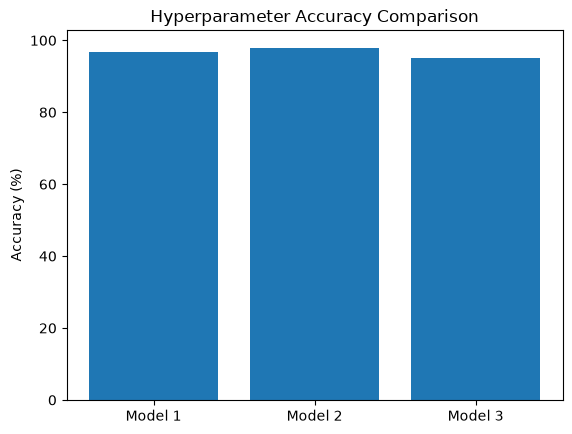

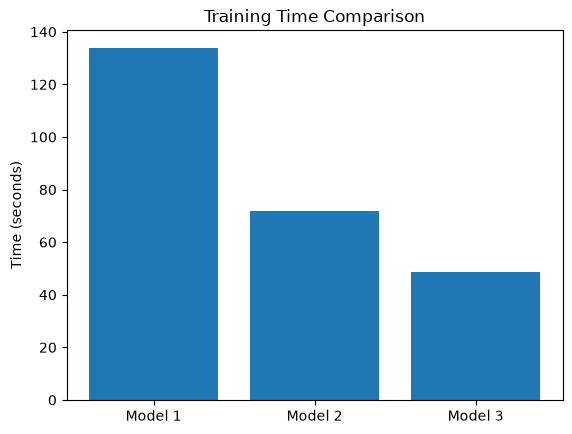

In [8]:
labels = ['Model 1', 'Model 2', 'Model 3']

plt.bar(labels, [r[3]*100 for r in results])
plt.title("Hyperparameter Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.show()

plt.bar(labels, [r[4] for r in results])
plt.title("Training Time Comparison")
plt.ylabel("Time (seconds)")
plt.show()

In [11]:
# tensorboard --logdir=logs (Run this in ubuntu terminal)